# Deteksi Penipuan Transaksi Keuangan dengan Machine Learning

Membuat  model untuk mendeteksi transaksi penipuan (fraud) dari data transaksi keuangan.

### Alur Pengerjaan
1. **Setup**: import library dan memuat dataset
2. **EDA**: memahami struktur data, kelas target, jenis transaksi, jumlah, saldo, waktu, pelanggan, dan korelasi
3. **Persiapan data**: memilih fitur, membagi data latih dan uji
4. **Modeling**: membuat pipeline preprocessing + Logistic Regression
5. **Evaluasi**: classification report dan confusion matrix
6. **Menyimpan model** untuk dipakai di aplikasi Streamlit

## Langkah 1: Setup
### 1.1 Import library

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


### 1.2 Pengaturan tampilan

In [2]:
import warnings
warnings.filterwarnings("ignore")
sns.set(style="whitegrid")

## Langkah 2: Memuat Dataset


In [3]:
df = pd.read_csv("AIML Dataset.csv")

df.head()

,step,type,amount,nameOrig,oldbalanceOrg,newbalanceOrig,nameDest,oldbalanceDest,newbalanceDest,isFraud,isFlaggedFraud
0,1,PAYMENT,9839.64,C1231006815,170136.0,160296.36,M1979787155,0.0,0.0,0,0
1,1,PAYMENT,1864.28,C1666544295,21249.0,19384.72,M2044282225,0.0,0.0,0,0
2,1,TRANSFER,181.00,C1305486145,181.0,0.00,C553264065,0.0,0.0,1,0
3,1,CASH_OUT,181.00,C840083671,181.0,0.00,C38997010,21182.0,0.0,1,0
4,1,PAYMENT,11668.14,C2048537720,41554.0,29885.86,M1230701703,0.0,0.0,0,0


## Langkah 3: Exploratory Data Analysis (EDA)
Tujuan EDA: memahami data sebelum membuat model.

### 3.1 Struktur data
Melihat tipe data, jumlah baris dan kolom, serta nama kolom.

In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 6362620 entries, 0 to 6362619
Data columns (total 11 columns):
 #   Column          Dtype  
---  ------          -----  
 0   step            int64  
 1   type            str    
 2   amount          float64
 3   nameOrig        str    
 4   oldbalanceOrg   float64
 5   newbalanceOrig  float64
 6   nameDest        str    
 7   oldbalanceDest  float64
 8   newbalanceDest  float64
 9   isFraud         int64  
 10  isFlaggedFraud  int64  
dtypes: float64(5), int64(3), str(3)
memory usage: 534.0 MB


In [5]:
print(df.columns)
print(df.shape)

Index(['step', 'type', 'amount', 'nameOrig', 'oldbalanceOrg', 'newbalanceOrig',
       'nameDest', 'oldbalanceDest', 'newbalanceDest', 'isFraud',
       'isFlaggedFraud'],
      dtype='str')
(6362620, 11)


### 3.2 Distribusi kelas target (`isFraud`)
Kolom `isFraud` adalah target: **1** = penipuan, **0** = transaksi normal.
Kolom `isFlaggedFraud` adalah penanda bawaan dari sistem dataset.

In [6]:
# Jumlah transaksi normal (0) dan penipuan (1)
df["isFraud"].value_counts()

isFraud
0    6354407
1       8213
Name: count, dtype: int64

In [7]:
# Jumlah transaksi yang ditandai otomatis oleh sistem (isFlaggedFraud)
df["isFlaggedFraud"].value_counts()

isFlaggedFraud
0    6362604
1         16
Name: count, dtype: int64

In [8]:
# Mengecek total data kosong (missing value) di seluruh dataset
df.isnull().sum().sum()

np.int64(0)

In [9]:
# Persentase transaksi penipuan terhadap seluruh transaksi
round((df["isFraud"].value_counts()[1] / df.shape[0]) * 100,2)

np.float64(0.13)

### 3.3 Analisis jenis transaksi (`type`)

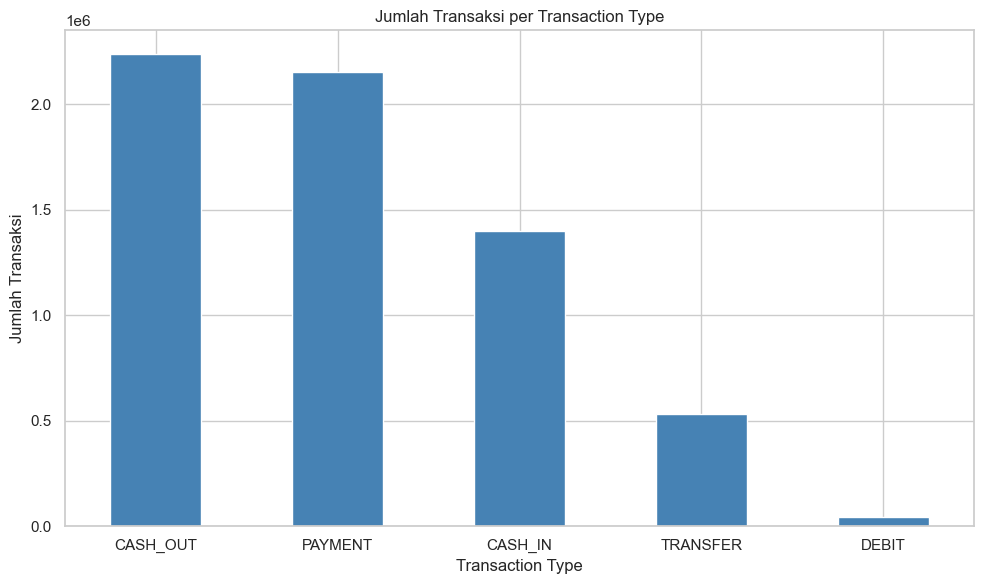

In [10]:
# Menghitung jumlah transaksi untuk tiap jenis transaksi
type_counts = df["type"].value_counts().sort_values(ascending=False)

plt.figure(figsize=(10, 6))
type_counts.plot(kind="bar", color="steelblue")
plt.title("Jumlah Transaksi per Transaction Type")
plt.xlabel("Transaction Type")
plt.ylabel("Jumlah Transaksi")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

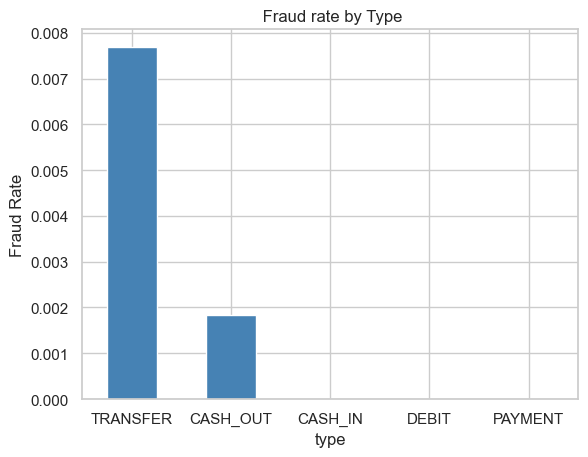

In [11]:
# Tingkat penipuan (rata-rata isFraud) untuk tiap jenis transaksi
fraud_by_type = df.groupby("type")["isFraud"].mean().sort_values(ascending=False)

fraud_by_type.plot(kind="bar",title=" Fraud rate by Type", color="steelblue")
plt.ylabel("Fraud Rate")
plt.xticks(rotation=0)
plt.show()

### 3.4 Analisis jumlah transaksi (`amount`)

In [12]:
# Statistik deskriptif jumlah transaksi (dibulatkan ke bilangan bulat)
df["amount"].describe().astype(int)

count     6362620
mean       179861
std        603858
min             0
25%         13389
50%         74871
75%        208721
max      92445516
Name: amount, dtype: int64

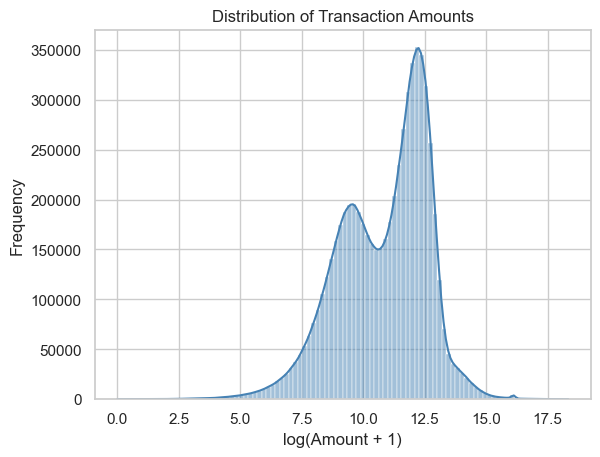

In [13]:
# Distribusi jumlah transaksi.
# log1p dipakai karena rentang nilainya sangat lebar (0 sampai puluhan juta)
sns.histplot(np.log1p(df["amount"]), bins=100, kde=True, color="steelblue")
plt.xlabel("log(Amount + 1)")
plt.ylabel("Frequency")
plt.title("Distribution of Transaction Amounts")
plt.show()

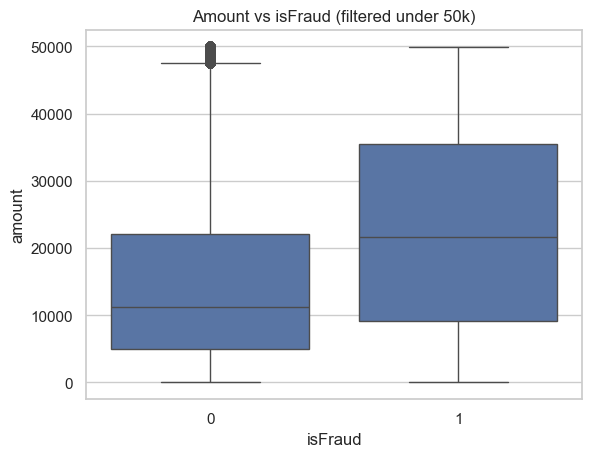

In [14]:
# Hubungan penipuan dengan jumlah transaksi.
sns.boxplot(data = df[df["amount"] < 50000], x="isFraud", y="amount")
plt.title("Amount vs isFraud (filtered under 50k)")
plt.show()

### 3.5 Rekayasa fitur: selisih saldo
Dibuat dua kolom baru untuk melihat perubahan saldo pengirim dan penerima. Selisih yang tidak wajar bisa menjadi tanda anomali.

In [15]:
df.columns

Index(['step', 'type', 'amount', 'nameOrig', 'oldbalanceOrg', 'newbalanceOrig',
       'nameDest', 'oldbalanceDest', 'newbalanceDest', 'isFraud',
       'isFlaggedFraud'],
      dtype='str')

In [16]:
# Selisih saldo pengirim: saldo lama - saldo baru
df["balanceDiffOrig"] = df["oldbalanceOrg"] - df["newbalanceOrig"]

# Selisih saldo penerima: saldo baru - saldo lama
df["balanceDiffDest"] = df["newbalanceDest"] - df["oldbalanceDest"]

In [17]:
# Menghitung selisih saldo yang bernilai negatif (tidak wajar).
(df["balanceDiffOrig"] < 0).sum()
(df["balanceDiffDest"] < 0).sum()

np.int64(1238864)

In [18]:
df.head(2)

,step,type,amount,nameOrig,oldbalanceOrg,newbalanceOrig,nameDest,oldbalanceDest,newbalanceDest,isFraud,isFlaggedFraud,balanceDiffOrig,balanceDiffDest
0,1,PAYMENT,9839.64,C1231006815,170136.0,160296.36,M1979787155,0.0,0.0,0,0,9839.64,0.0
1,1,PAYMENT,1864.28,C1666544295,21249.0,19384.72,M2044282225,0.0,0.0,0,0,1864.28,0.0


### 3.6 Penipuan berdasarkan waktu (`step`)
`step` adalah satuan waktu dalam dataset (1 step = 1 jam).

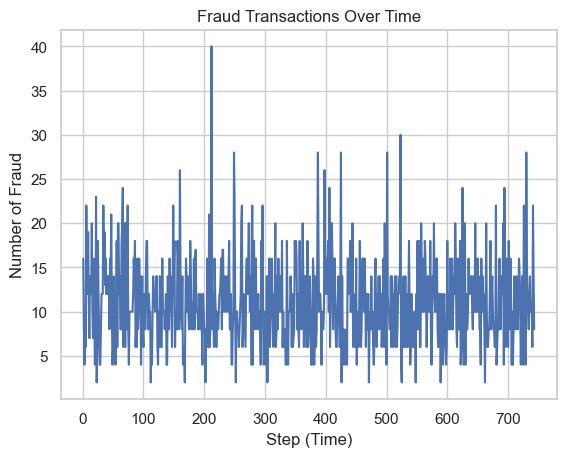

In [19]:
fraud_per_step = df[df["isFraud"] == 1]["step"].value_counts().sort_index()
plt.plot(fraud_per_step.index, fraud_per_step.values, label ="Fraud per Step")
plt.xlabel("Step (Time)")
plt.ylabel("Number of Fraud")
plt.title("Fraud Transactions Over Time")
plt.grid (True)
plt.show()

In [20]:
#ternyata step tidak berpengaruh terhadap jumlah sehingga kita hapus step
df.drop(columns=["step"], inplace=True)

### 3.7 Analisis pelanggan
Melihat pengirim dan penerima yang paling sering muncul, serta pengirim yang tercatat melakukan penipuan.

In [21]:
# Top 10 pelanggan pengirim dengan transaksi terbanyak
top_senders = df["nameOrig"].value_counts().head(10)
top_senders

nameOrig
C2098525306    3
C400299098     3
C1999539787    3
C1065307291    3
C545315117     3
C1976208114    3
C1784010646    3
C1530544995    3
C1902386530    3
C1677795071    3
Name: count, dtype: int64

In [22]:
# Top 10 pelanggan penerima dengan transaksi terbanyak
top_receivers = df["nameDest"].value_counts().head(10)
top_receivers

nameDest
C1286084959    113
C985934102     109
C665576141     105
C2083562754    102
C248609774     101
C1590550415    101
C451111351      99
C1789550256     99
C1360767589     98
C1023714065     97
Name: count, dtype: int64

In [23]:
# Top 10 pengirim yang tercatat melakukan penipuan
fraud_Users = df[df["isFraud"] == 1]["nameOrig"].value_counts().head(10)
fraud_Users

nameOrig
C1305486145    1
C840083671     1
C1420196421    1
C2101527076    1
C137533655     1
C1118430673    1
C749981943     1
C1334405552    1
C467632528     1
C1364127192    1
Name: count, dtype: int64

### 3.8 Penipuan pada transaksi TRANSFER dan CASH_OUT

In [24]:
fraud_types = df[df["type"].isin(["TRANSFER", "CASH_OUT"])]
fraud_types["type"].value_counts()

type
CASH_OUT    2237500
TRANSFER     532909
Name: count, dtype: int64

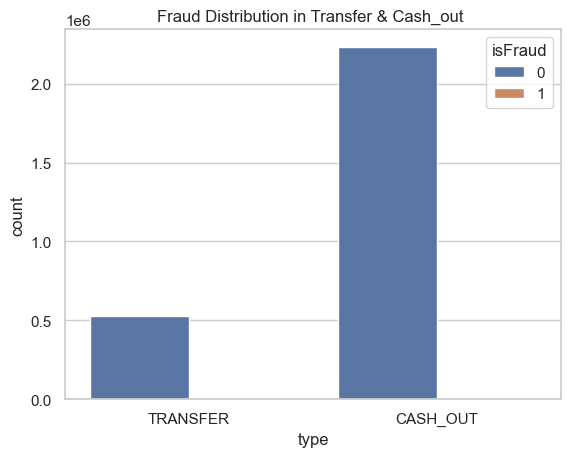

In [25]:
# Perbandingan transaksi normal dan penipuan pada TRANSFER dan CASH_OUT
sns.countplot(data=fraud_types, x="type", hue="isFraud")
plt.title("Fraud Distribution in Transfer & Cash_out ")
plt.show()

**Catatan:** pada grafik ini jumlah penipuan sangat kecil dibanding transaksi normal sehingga batang penipuan hampir tidak terlihat. Terlihat juga bahwa `CASH_OUT` jauh lebih banyak dibanding `TRANSFER`. Selanjutnya kita lihat korelasi antar fitur.

### 3.9 Korelasi antar fitur numerik

In [26]:
corr = df[["amount","oldbalanceOrg","newbalanceOrig","oldbalanceDest","newbalanceDest","isFraud"]].corr()
corr

,amount,oldbalanceOrg,newbalanceOrig,oldbalanceDest,newbalanceDest,isFraud
amount,1.000000,-0.002762,-0.007861,0.294137,0.459304,0.076688
oldbalanceOrg,-0.002762,1.000000,0.998803,0.066243,0.042029,0.010154
newbalanceOrig,-0.007861,0.998803,1.000000,0.067812,0.041837,-0.008148
oldbalanceDest,0.294137,0.066243,0.067812,1.000000,0.976569,-0.005885
newbalanceDest,0.459304,0.042029,0.041837,0.976569,1.000000,0.000535
isFraud,0.076688,0.010154,-0.008148,-0.005885,0.000535,1.000000


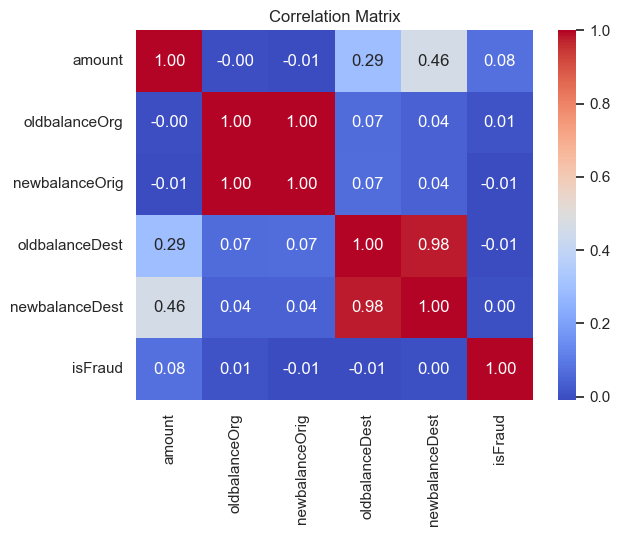

In [27]:
#heatmap of correlation matrix
sns.heatmap(corr, annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Correlation Matrix")
plt.show()

### 3.10 Pola mencurigakan: saldo pengirim menjadi nol
Mencari transaksi TRANSFER atau CASH_OUT yang mengosongkan seluruh saldo pengirim.

In [28]:
# lalu mencari transaksi transfer atau tarik tunai yang membuat saldo pengirim menjadi nol. 
zero_after_transfer = df[
    (df["oldbalanceOrg"] > 0) &
    (df["newbalanceOrig"] == 0) &
    (df["type"].isin(["TRANSFER", "CASH_OUT"]))  
]

In [29]:
# Jumlah transaksi dengan pola saldo pengirim menjadi nol
len(zero_after_transfer)

1188074

**Catatan:** terdapat 1.188.074 transaksi dengan pola ini. Transaksi tersebut belum tentu penipuan; ini hanya hasil penyaringan berdasarkan pola saldo.

In [30]:
zero_after_transfer.head()

,type,amount,nameOrig,oldbalanceOrg,newbalanceOrig,nameDest,oldbalanceDest,newbalanceDest,isFraud,isFlaggedFraud,balanceDiffOrig,balanceDiffDest
2,TRANSFER,181.00,C1305486145,181.0,0.0,C553264065,0.0,0.00,1,0,181.0,0.00
3,CASH_OUT,181.00,C840083671,181.0,0.0,C38997010,21182.0,0.00,1,0,181.0,-21182.00
15,CASH_OUT,229133.94,C905080434,15325.0,0.0,C476402209,5083.0,51513.44,0,0,15325.0,46430.44
19,TRANSFER,215310.30,C1670993182,705.0,0.0,C1100439041,22425.0,0.00,0,0,705.0,-22425.00
24,TRANSFER,311685.89,C1984094095,10835.0,0.0,C932583850,6267.0,2719172.89,0,0,10835.0,2712905.89


### 3.11 Ketidakseimbangan kelas (*class imbalance*)

In [31]:
# Jumlah kelas penipuan dan normal (diulang untuk melihat ketidakseimbangan kelas)
df["isFraud"].value_counts()

isFraud
0    6354407
1       8213
Name: count, dtype: int64

kelas sangat tidak seimbang (8.213 penipuan vs 6.354.407 normal, sekitar 0,13%).

## Langkah 4: Feature Engineering & Training a ML Model
Bagian ini memilih fitur, membagi data, lalu melatih model.

### 4.1 Import library untuk modeling

In [32]:
# Pembagian data dan evaluasi
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# Preprocessing dan pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, confusion_matrix
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.metrics import ConfusionMatrixDisplay


### 4.2 Memilih fitur
Kolom identitas (`nameOrig`, `nameDest`) dan `isFlaggedFraud` dibuang dari data model.

In [33]:
# nameOrig dan nameDest (identitas pelanggan), isFlaggedFraud (penanda bawaan sistem)
df_model = df.drop(["nameOrig", "nameDest", "isFlaggedFraud"], axis=1)

In [34]:
df_model.head()

,type,amount,oldbalanceOrg,newbalanceOrig,oldbalanceDest,newbalanceDest,isFraud,balanceDiffOrig,balanceDiffDest
0,PAYMENT,9839.64,170136.0,160296.36,0.0,0.0,0,9839.64,0.0
1,PAYMENT,1864.28,21249.0,19384.72,0.0,0.0,0,1864.28,0.0
2,TRANSFER,181.00,181.0,0.00,0.0,0.0,1,181.00,0.0
3,CASH_OUT,181.00,181.0,0.00,21182.0,0.0,1,181.00,-21182.0
4,PAYMENT,11668.14,41554.0,29885.86,0.0,0.0,0,11668.14,0.0


### 4.3 Menentukan kolom kategorikal dan numerik

In [35]:
catergorical = ["type"]
numeric = ["amount", "oldbalanceOrg", "newbalanceOrig", "oldbalanceDest", "newbalanceDest"]


### 4.4 Memisahkan fitur (X) dan target (y)

In [36]:
y = df_model["isFraud"]
X = df_model.drop("isFraud", axis=1)

### 4.5 Membagi data latih dan data uji
70% data untuk latih, 30% untuk uji. `stratify=y` menjaga proporsi penipuan tetap sama di kedua bagian.

In [37]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, stratify=y)

## Langkah 5: Membuat Pipeline Model
### 5.1 Preprocessing
- Kolom numerik diskalakan dengan `StandardScaler`
- Kolom kategorikal `type` diubah menjadi angka dengan `OneHotEncoder`

In [38]:
preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), numeric),
        ("cat", OneHotEncoder(), catergorical)
    ],
    remainder="drop"
)        

In [39]:
pipeline = Pipeline([
    ("prep", preprocessor),
    ("clf", LogisticRegression(class_weight="balanced", max_iter=1000))
])

### 5.2 Melatih model

In [40]:
pipeline.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('prep', ...), ('clf', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](8,)","['type','amount','oldbalanceOrg',...,'newbalanceDest','balanceDiffOrig', 'balanceDiffDest']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,8
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'

## Langkah 6: Evaluasi Model
### 6.1 Prediksi pada data uji

In [41]:
y_pred = pipeline.predict(X_test)

In [42]:
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       1.00      0.95      0.97   1906322
           1       0.02      0.95      0.04      2464

    accuracy                           0.95   1908786
   macro avg       0.51      0.95      0.51   1908786
weighted avg       1.00      0.95      0.97   1908786



**Interpretasi hasil:**
- **Recall penipuan 0,94**: model berhasil menangkap sekitar 94% transaksi penipuan.
- **Precision penipuan 0,02**: dari semua transaksi yang diprediksi penipuan, hanya sekitar 2% yang benar-benar penipuan, jadi banyak transaksi normal yang salah ditandai (*false positive*).
- Akurasi tinggi (sekitar 95%) namun kelas sangat tidak seimbang. Recall, precision, dan f1-score kelas penipuan lebih relevan.

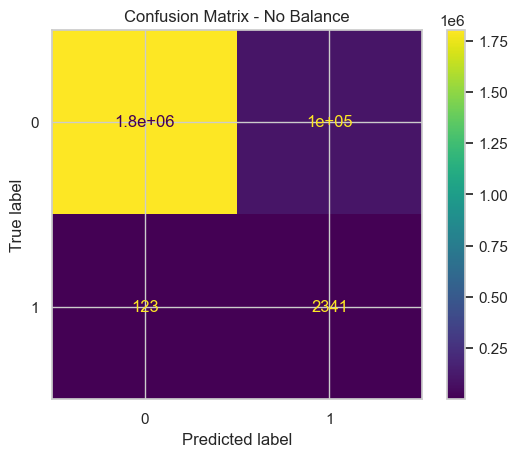

In [43]:
ConfusionMatrixDisplay.from_predictions(y_test, y_pred)
plt.title("Confusion Matrix - No Balance")
plt.show()

In [44]:
# Akurasi model pada data uji (dalam persen)
pipeline.score(X_test, y_test) * 100

94.62124093533795

## Langkah 7: Menyimpan Model
Pipeline disimpan ke file `.pkl` agar bisa dimuat oleh aplikasi Streamlit (`fraud_detection.py`).

In [46]:
import joblib

joblib.dump(pipeline, "models/fraud_detection_pipeline.pkl")


['models/fraud_detection_pipeline.pkl']

---
## Kesimpulan
- Penipuan hanya sekitar 0,13% dari seluruh transaksi, sehingga data sangat tidak seimbang.
- Model Logistic Regression dengan `class_weight="balanced"` memiliki recall penipuan yang tinggi, tetapi precision yang rendah.
- Pengembangan berikutnya: mencoba model lain (misalnya Random Forest atau XGBoost), memakai fitur selisih saldo, mengatur *threshold* prediksi, atau teknik penanganan imbalance seperti SMOTE.